# Chapter 5. From a line to a probability

*Logistic regression: probability, direction, strength.*

Marketing's question is "will this member buy again", a yes or a no. Twelve Kalpa members, invented for teaching, show why a straight line is the wrong tool for that question and how bending it into an S fixes it. The S gives a probability, its sign gives the direction, and the size of its coefficient gives the strength.

By the end you can say what a logistic output of 0.73 means, read a coefficient as a multiplier on the odds, and explain why the line fails at the ends.

**Search terms:** logistic regression, sigmoid function, odds and log-odds, odds ratio, StatQuest logistic regression.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Twelve Kalpa members, invented for teaching: visits last quarter and whether they bought again in 90 days.
members = pd.DataFrame({"visits": [0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 6, 7],
                        "repeat_90d": [0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1]})
print(members.T.to_string(header=False))

visits      0  1  1  2  2  3  3  4  4  5  6  7
repeat_90d  0  0  0  0  1  0  1  1  0  1  1  1


## What goes wrong if we fit a line?

A straight line fitted to 0s and 1s gives a number for every member. Read it as a probability and see what happens at the ends.

**Predict before you run.** For a member with 8 visits, the straight line predicts (a) about 0.9 (b) exactly 1.0 (c) more than 1.0

In [3]:
# The straight line on yes/no data, and what it says at 0 and at 8 visits.
from sklearn.linear_model import LinearRegression, LogisticRegression
line = LinearRegression().fit(members[["visits"]], members["repeat_90d"])
at = pd.DataFrame({"visits": [0, 4, 8]})
print(pd.DataFrame({"visits": at["visits"], "line_says": line.predict(at).round(2)}).to_string(index=False))
check("the line leaves the 0 to 1 range at 8 visits", line.predict(pd.DataFrame({"visits": [8]}))[0] > 1)

 visits  line_says
      0      -0.01
      4       0.63
      8       1.28
PASS  the line leaves the 0 to 1 range at 8 visits


**What happened.** The answer is (c): 1.28, a "probability" above 1, which no member can have. The line also dips to -0.01 at zero visits. A line keeps rising forever; a probability has to flatten out near 0 and near 1.

## Bend the line into an S

Logistic regression keeps a straight line underneath, `z = a + b x visits`, and squeezes it through the S-shaped function `p = 1 / (1 + exp(-z))`, which can never leave 0 to 1.

z = -3.20 + 1.05 x visits
a member with 4 visits: p = 0.73 from the model, 0.73 from the formula
PASS  the model's probability equals the formula's
PASS  every probability on the grid stays between 0 and 1


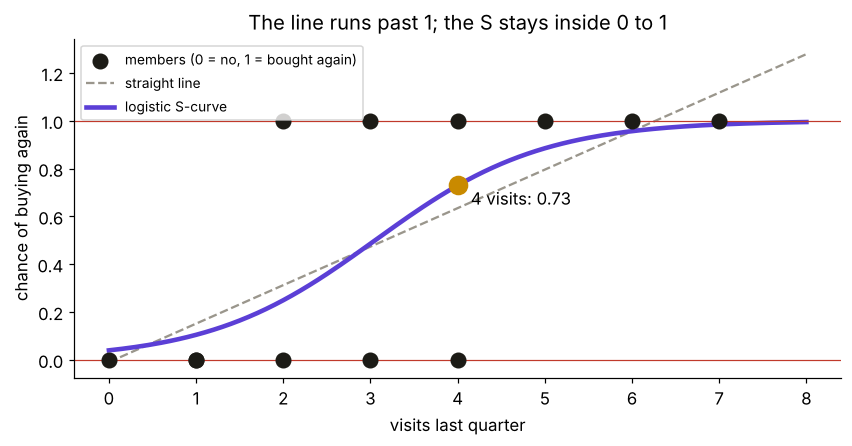

In [4]:
# Fit the logistic model without a penalty, so the numbers match the formula exactly.
logit = LogisticRegression(C=1e6).fit(members[["visits"]], members["repeat_90d"])
a, b = logit.intercept_[0], logit.coef_[0][0]
grid = pd.DataFrame({"visits": np.linspace(0, 8, 161)})
print(f"z = {a:.2f} + {b:.2f} x visits")
p4 = logit.predict_proba(pd.DataFrame({"visits": [4]}))[0, 1]
by_formula = 1 / (1 + np.exp(-(a + b * 4)))
print(f"a member with 4 visits: p = {p4:.2f} from the model, {by_formula:.2f} from the formula")
check("the model's probability equals the formula's", abs(p4 - by_formula) < 1e-9)
check("every probability on the grid stays between 0 and 1", logit.predict_proba(grid)[:, 1].min() > 0 and logit.predict_proba(grid)[:, 1].max() < 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(members["visits"], members["repeat_90d"], s=90, color="#1C1B16", zorder=3, label="members (0 = no, 1 = bought again)")
ax.plot(grid["visits"], line.predict(grid), color="#9A968C", ls="--", label="straight line")
ax.plot(grid["visits"], logit.predict_proba(grid)[:, 1], color="#5B3FD6", lw=3, label="logistic S-curve")
ax.axhline(1, color="#C0392B", lw=0.8); ax.axhline(0, color="#C0392B", lw=0.8)
ax.scatter([4], [p4], s=140, color="#C98A00", zorder=4); ax.text(4.15, p4 - 0.08, f"4 visits: {p4:.2f}")
ax.set_xlabel("visits last quarter"); ax.set_ylabel("chance of buying again"); ax.legend(loc="upper left", fontsize=9)
ax.set_title("The line runs past 1; the S stays inside 0 to 1")
plt.show()

**What 0.73 means.** Of 100 members who look like this one (4 visits), about 73 would buy again within 90 days, if the model is calibrated. It is a statement about a group of similar members, never a promise about this one.

## Direction and strength

**Direction** is the sign of `b`. Here `b` is positive, so more visits go with a higher chance of buying again.

**Strength** is the size of `b`, read through `exp(b)`: each extra visit multiplies the odds of buying again by that factor. Odds are p / (1 - p): a probability of 0.75 is odds of 3 to 1.

In [5]:
# Read the coefficient as a multiplier on the odds, then confirm it on two neighbouring members.
odds = lambda p: p / (1 - p)
p3 = logit.predict_proba(pd.DataFrame({"visits": [3]}))[0, 1]
print(f"exp(b) = {np.exp(b):.2f}: each extra visit multiplies the odds by about {np.exp(b):.1f}")
print(f"3 visits: p = {p3:.2f}, odds {odds(p3):.2f};  4 visits: p = {p4:.2f}, odds {odds(p4):.2f};  ratio {odds(p4) / odds(p3):.2f}")
check("the odds ratio between 3 and 4 visits equals exp(b)", abs(odds(p4) / odds(p3) - np.exp(b)) < 1e-9)

exp(b) = 2.85: each extra visit multiplies the odds by about 2.8
3 visits: p = 0.49, odds 0.94;  4 visits: p = 0.73, odds 2.69;  ratio 2.85
PASS  the odds ratio between 3 and 4 visits equals exp(b)


**The trap.** "Each extra visit adds 1.05 to the probability" reads the coefficient as if it were a line's slope. It adds 1.05 to the log-odds, which multiplies the odds by 2.85; the change in probability depends on where you start (0.25 to 0.49 from 2 to 3 visits, 0.88 to 0.96 from 5 to 6).

**The flip.** Logistic regression gives one direction per input. If the chance of buying rises at both ends of an input (very new and very old members both come back more), one S cannot hold it; chapter 6 shows that failure.

## What did this chapter establish?

| Question | Answer |
|---|---|
| Why not a line? | it predicts 1.28 at 8 visits and -0.01 at 0, outside 0 to 1 |
| What does logistic regression output? | a probability: 0.73 means about 73 of 100 similar members buy again |
| Direction | the sign of b: positive, more visits, more likely |
| Strength | exp(b) = 2.85: each extra visit multiplies the odds by about 2.85 |

**Interview line:** "A logistic output of 0.71 means that among customers who look like this one, about 71 in 100 do the thing, if the model is calibrated; the coefficient's sign is the direction and exp of it is the multiplier on the odds."